# Lab 03 — 02. Feature Engineering & Preprocessing

Notebook thực hiện kỹ nghệ đặc trưng và tiền xử lý văn bản chuẩn 6 bước theo [`docs/feature.md`](../../../docs/feature.md) cho bài toán phân loại sắc thái cảm xúc (Sentiment Analysis). Hỗ trợ chế độ kép: `MODE="view"` để đọc các artifact đã xuất bản và `MODE="prepare"` để chạy trích xuất lại.

## Bảng Lộ Trình Triển Khai Thực Tế (Pipeline Execution Roadmap)

| Bước | Giai đoạn (Phase) | Nội dung chi tiết (Core Description) | Module triển khai / Hàm thực thi | Sản phẩm đầu ra (Output / Artifact) |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Setup & Khởi tạo phiên** | Nạp NotebookSession, xác định đường dẫn artifact từ latest_preparation và cấu hình thực thi. | [src/notebook_runtime.py](../src/notebook_runtime.py): `NotebookSession` | Instance `session`, biến `MODE`, đường dẫn artifacts |
| **2** | **Bước 1 & 2: Xử lý ngoại lệ & Cutoff độ dài** | Phân tích độ nhạy cắt cụt câu (truncation sensitivity) tại các ngưỡng 64, 96, 128, 256. Khóa ngưỡng an toàn max_length=128 (tỷ lệ cắt < 0.2%). | [src/data_preparation.py](../src/data_preparation.py): `export_data_review` | `preprocessing_diagnostics.png`, `preprocessing_statistics.json` |
| **3** | **Bước 3: Tokenization & Dynamic Padding** | Mã hóa văn bản qua DistilBERT WordPiece Tokenizer, kiểm tra phân rã subwords, tensors input_ids và attention_mask thực tế. | [src/data_preparation.py](../src/data_preparation.py): `export_data_review` | `tokenization_examples.json`, `preprocessing_examples.png`, `attention_mask.png` |
| **4** | **Bước 4: Tạo đặc trưng ngôn ngữ học (Handcrafted)** | Trích xuất các đặc trưng dense: tỷ lệ chữ hoa (uppercase ratio), tỷ lệ dấu câu (punctuation ratio), độ dài trung bình của từ, và từ ngữ chỉ thị phủ định / tương phản. | [src/data_preparation.py](../src/data_preparation.py): `extract_linguistic_features` | `linguistic_features.json`, `linguistic_features.png`, `negation_contrast_by_label.png` |
| **5** | **Bước 5: Vector hóa văn bản TF-IDF** | Trích xuất không gian đặc trưng TF-IDF unigram & bigram (min_df=2, max_features=50.000, sublinear_tf=True) hoàn toàn trên train-only để làm baseline. | [src/data_preparation.py](../src/data_preparation.py): `make_tfidf` | `feature_summary.json`, `tfidf_features.png`, `tfidf_class_delta.png` |
| **6** | **Bước 6: Lựa chọn đặc trưng bằng Chi-Square ($\chi^2$)** | Thực hiện kiểm định thống kê Chi-Square giữa ma trận TF-IDF và nhãn sentiment để lọc ra Top 25 n-grams có năng lực phân biệt mạnh nhất. | [src/data_preparation.py](../src/data_preparation.py): `select_chi2_features` | `chi2_features.json`, `chi2_features.png` |
| **7** | **Bước 7: Tăng cường dữ liệu có kiểm soát (Augmentation)** | Mở rộng tập huấn luyện bằng kỹ thuật chèn/thay thế ngữ cảnh, có chốt bảo vệ từ phủ định (negation protection) và kiểm toán rò rỉ nhãn. | [src/datasets/augmentation.py](../src/datasets/augmentation.py): `augment_split` | `augmentation.json`, `augmentation_counts.png`, `augmentation_examples.png` |

## 1. Setup và cấu hình phiên làm việc

In [1]:
from pathlib import Path
import subprocess, sys, json
MODE = "view"
DEVICE = "cpu"
REPO_URL = "https://github.com/lacthui06/Lab-DL.git"
REPO_REF = "lab03"
start = Path.cwd().resolve()
REPO = next((p for p in (start,*start.parents) if (p/"labs/lab03/config/frozen_trial.json").is_file()), None)
if REPO is None and Path("/kaggle/working").is_dir():
    REPO = Path("/kaggle/working/Lab-DL")
    if not REPO.exists():
        subprocess.run(["git","clone","--branch",REPO_REF,"--single-branch",REPO_URL,str(REPO)],check=True)
assert REPO is not None, "Mở notebook trong repository hoặc trên Kaggle."
sys.path.insert(0,str(REPO))
from labs.lab03.src.notebook_runtime import NotebookSession
session = NotebookSession(REPO, MODE, DEVICE)
session.setup()
from IPython.display import display


MODE=view: đọc artifacts đã lưu; không cài/tải model, không training.


## 2. Bước 1 & 2: Xử lý ngoại lệ độ dài và chiến lược Truncation Cutoff

Quyết định cắt cụt chuỗi (Truncation Decision):
  - Max length đã chọn: 128
  - Tỷ lệ mẫu train bị cắt: 0.00%
  - Khuyến nghị: Keep the configured cutoff; the observed train overflow is below 5%. Do not add a special truncation strategy without evidence.


**preprocessing_diagnostics.png**

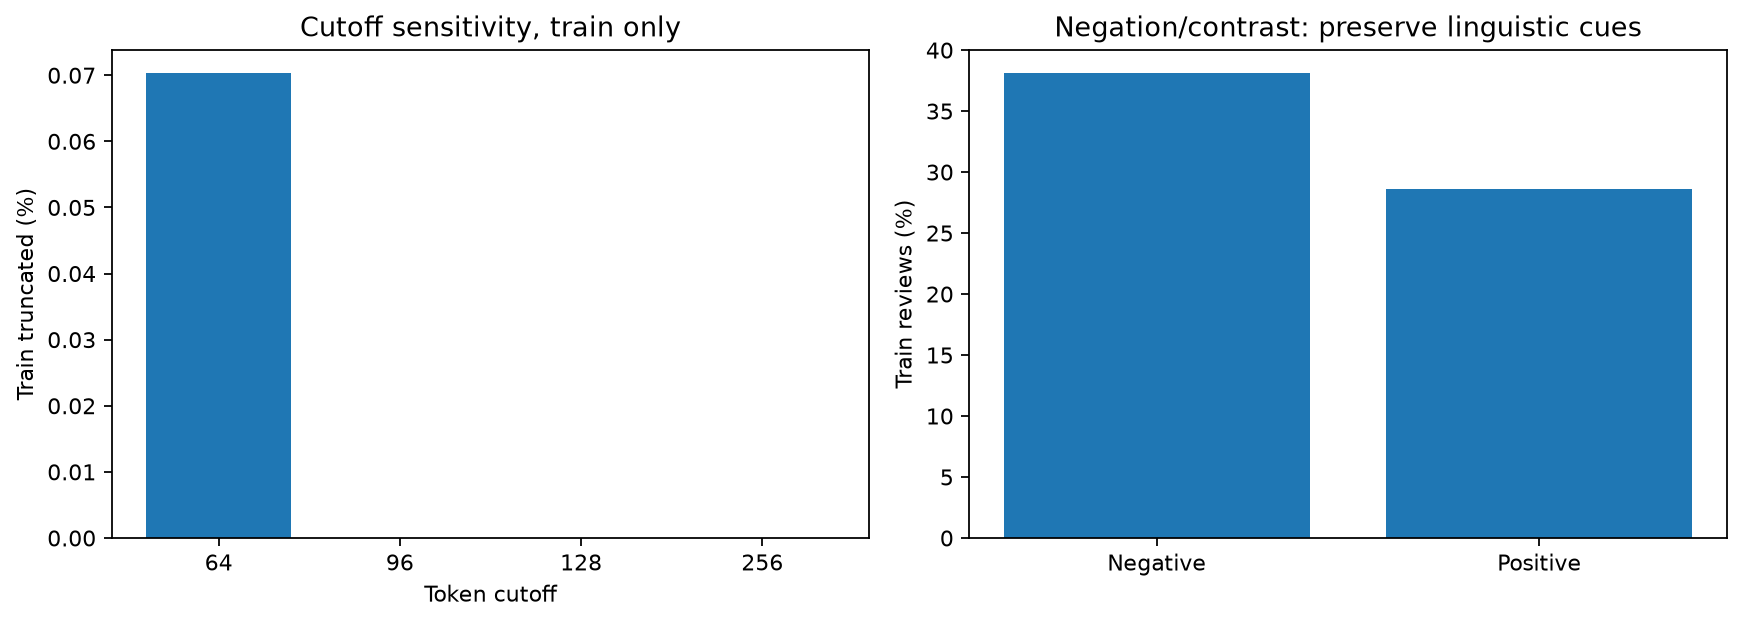

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/preprocessing_diagnostics.png')]

In [2]:
preprocessing = session.read(session.paths["data"] / "preprocessing_statistics.json")
print("Quyết định cắt cụt chuỗi (Truncation Decision):")
print(f"  - Max length đã chọn: {preprocessing['configured_max_length']}")
print(f"  - Tỷ lệ mẫu train bị cắt: {preprocessing['configured_cutoff_overflow_fraction']:.2%}")
print(f"  - Khuyến nghị: {preprocessing['configured_cutoff_decision']}")

session.show("data", ["preprocessing_diagnostics.png"])

## 3. Bước 3: Tokenization và Dynamic Padding cho Transformer

,text,tokens_preview,ids_preview
0,"simplistic , silly and tedious .","[CLS] sim ##pl ##istic , silly and ted ##ious ...",101 21934 24759 6553 1010 10021 1998 6945 6313...
1,"it's so laddish and juvenile , only teenage bo...","[CLS] it ' s so lad ##dis ##h and juvenile , only",101 2009 1005 1055 2061 14804 10521 2232 1998 ...
2,the rock is destined to be the 21st century's ...,[CLS] the rock is destined to be the 21st cent...,101 1996 2600 2003 16036 2000 2022 1996 7398 2...
3,"the gorgeously elaborate continuation of "" the...",[CLS] the gorgeous ##ly elaborate continuation...,101 1996 9882 2135 9603 13633 1997 1000 1996 2...


**preprocessing_examples.png**

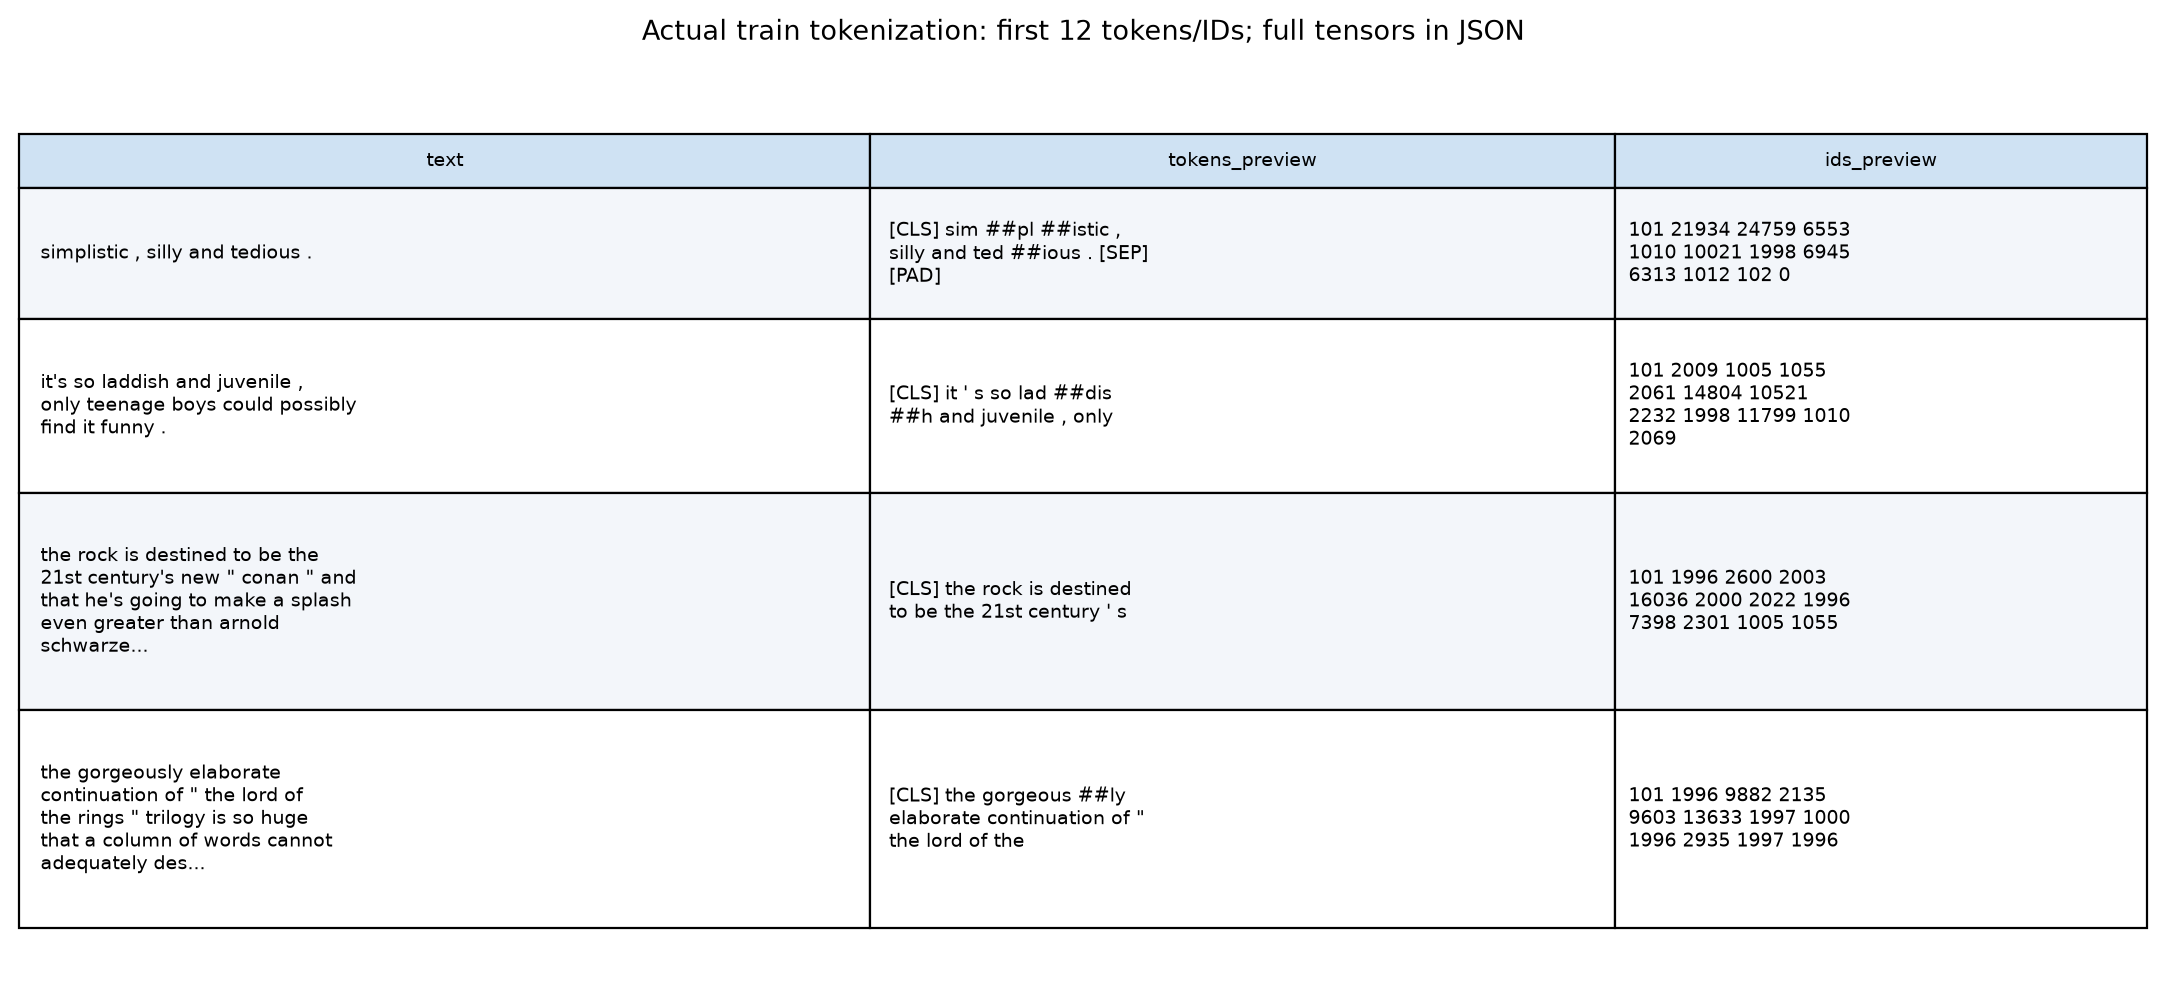

**attention_mask.png**

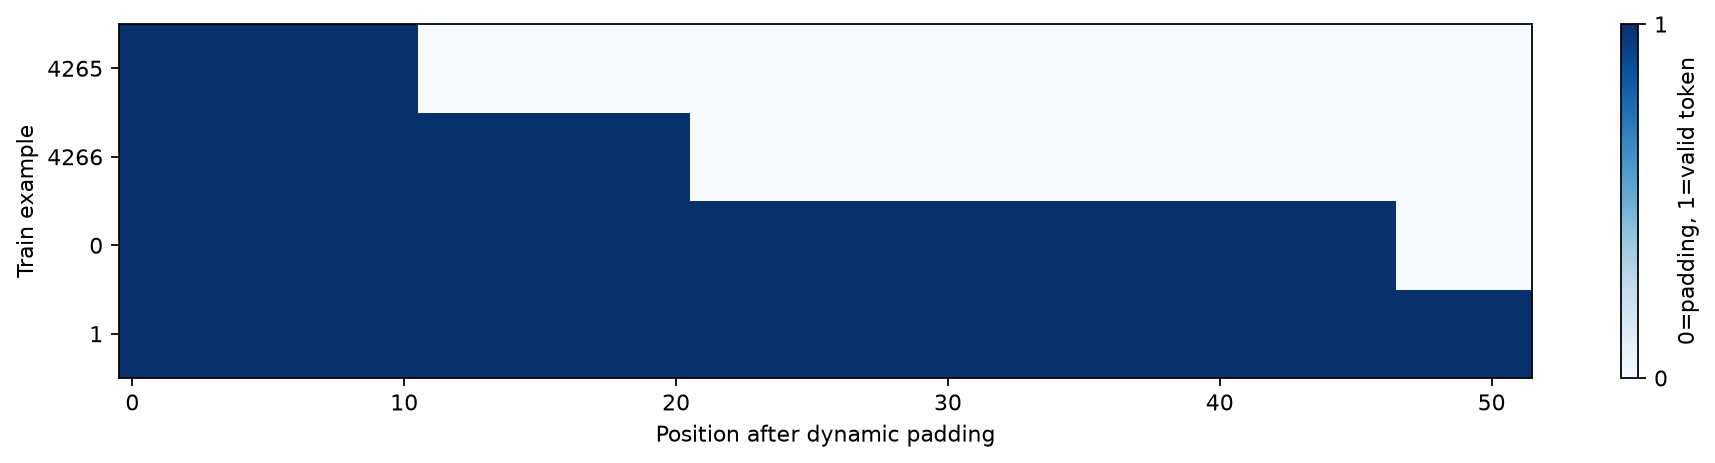

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/preprocessing_examples.png'),
 WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/attention_mask.png')]

In [3]:
from IPython.display import display

display(session.table("data", "tokenization_examples.json", columns=["text", "tokens_preview", "ids_preview"]))
session.show("data", ["preprocessing_examples.png", "attention_mask.png"])

## 4. Bước 4: Tạo đặc trưng ngôn ngữ học (Linguistic Handcrafted Features)

,label_0_mean,label_1_mean,overall_mean
char_count,112.772098,115.171161,113.971630
word_count,20.937632,21.048066,20.992849
avg_word_length,4.476715,4.576160,4.526437
uppercase_ratio,0.000000,0.000006,0.000003
punctuation_ratio,0.029880,0.028772,0.029326
digit_fraction,0.057210,0.046424,0.051817
negation_cue_count,0.309496,0.200938,0.255217
contrast_cue_count,0.192497,0.180305,0.186401


**linguistic_features.png**

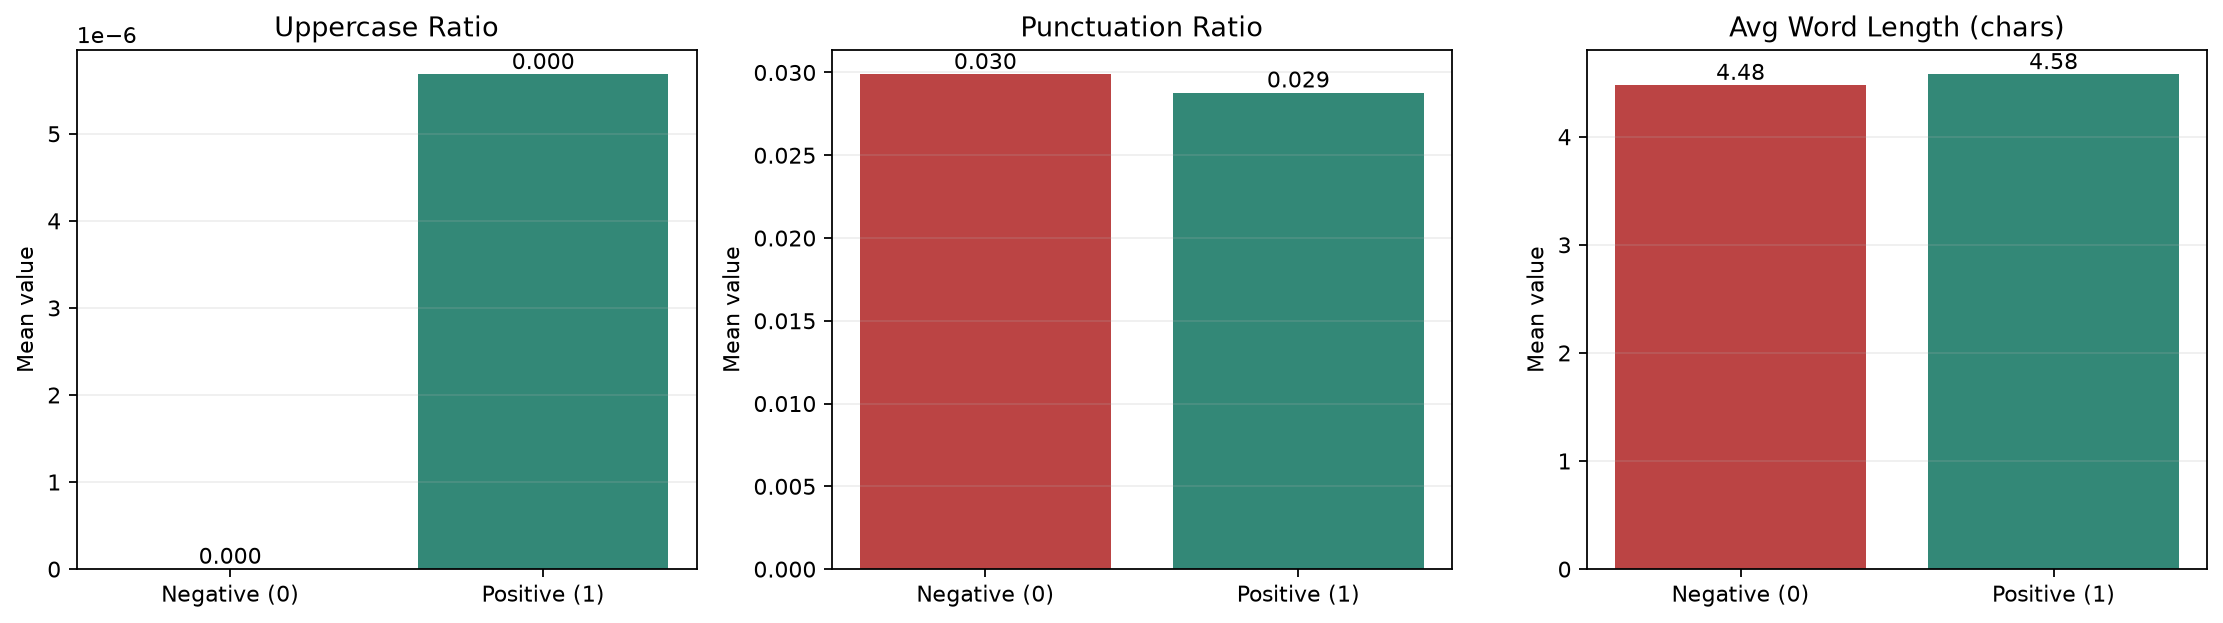

**negation_contrast_by_label.png**

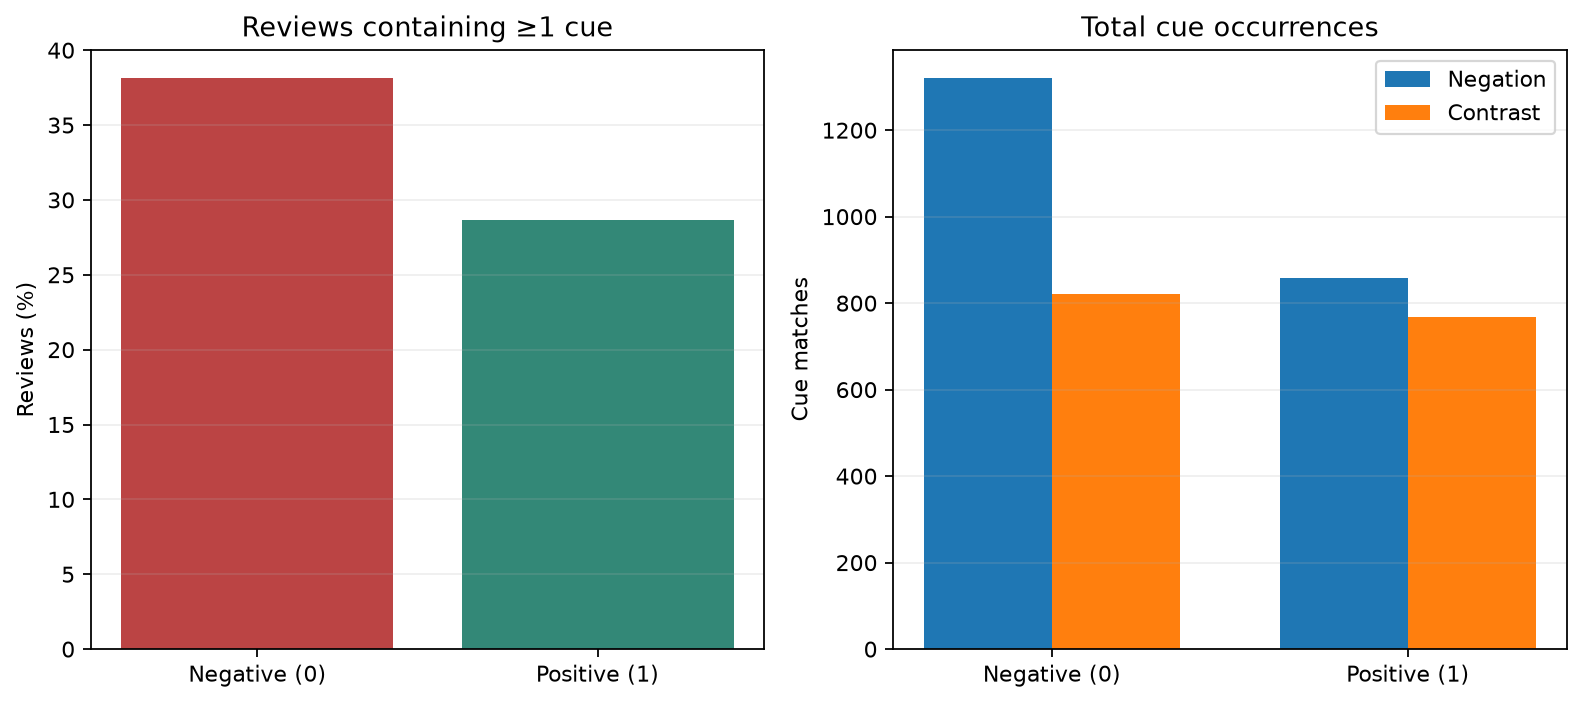

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/linguistic_features.png'),
 WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/negation_contrast_by_label.png')]

In [4]:
import pandas as pd
from IPython.display import display

ling_data = session.read(session.paths["data"] / "linguistic_features.json")
display(pd.DataFrame(ling_data.get("metrics", {})).T)

session.show("data", ["linguistic_features.png", "negation_contrast_by_label.png"])

## 5. Bước 5: Vector hóa văn bản TF-IDF (Unigram & Bigram)

Ma trận TF-IDF Train Shape: [8530, 24083]
Độ thưa (Sparsity Density): 0.1012%


**tfidf_features.png**

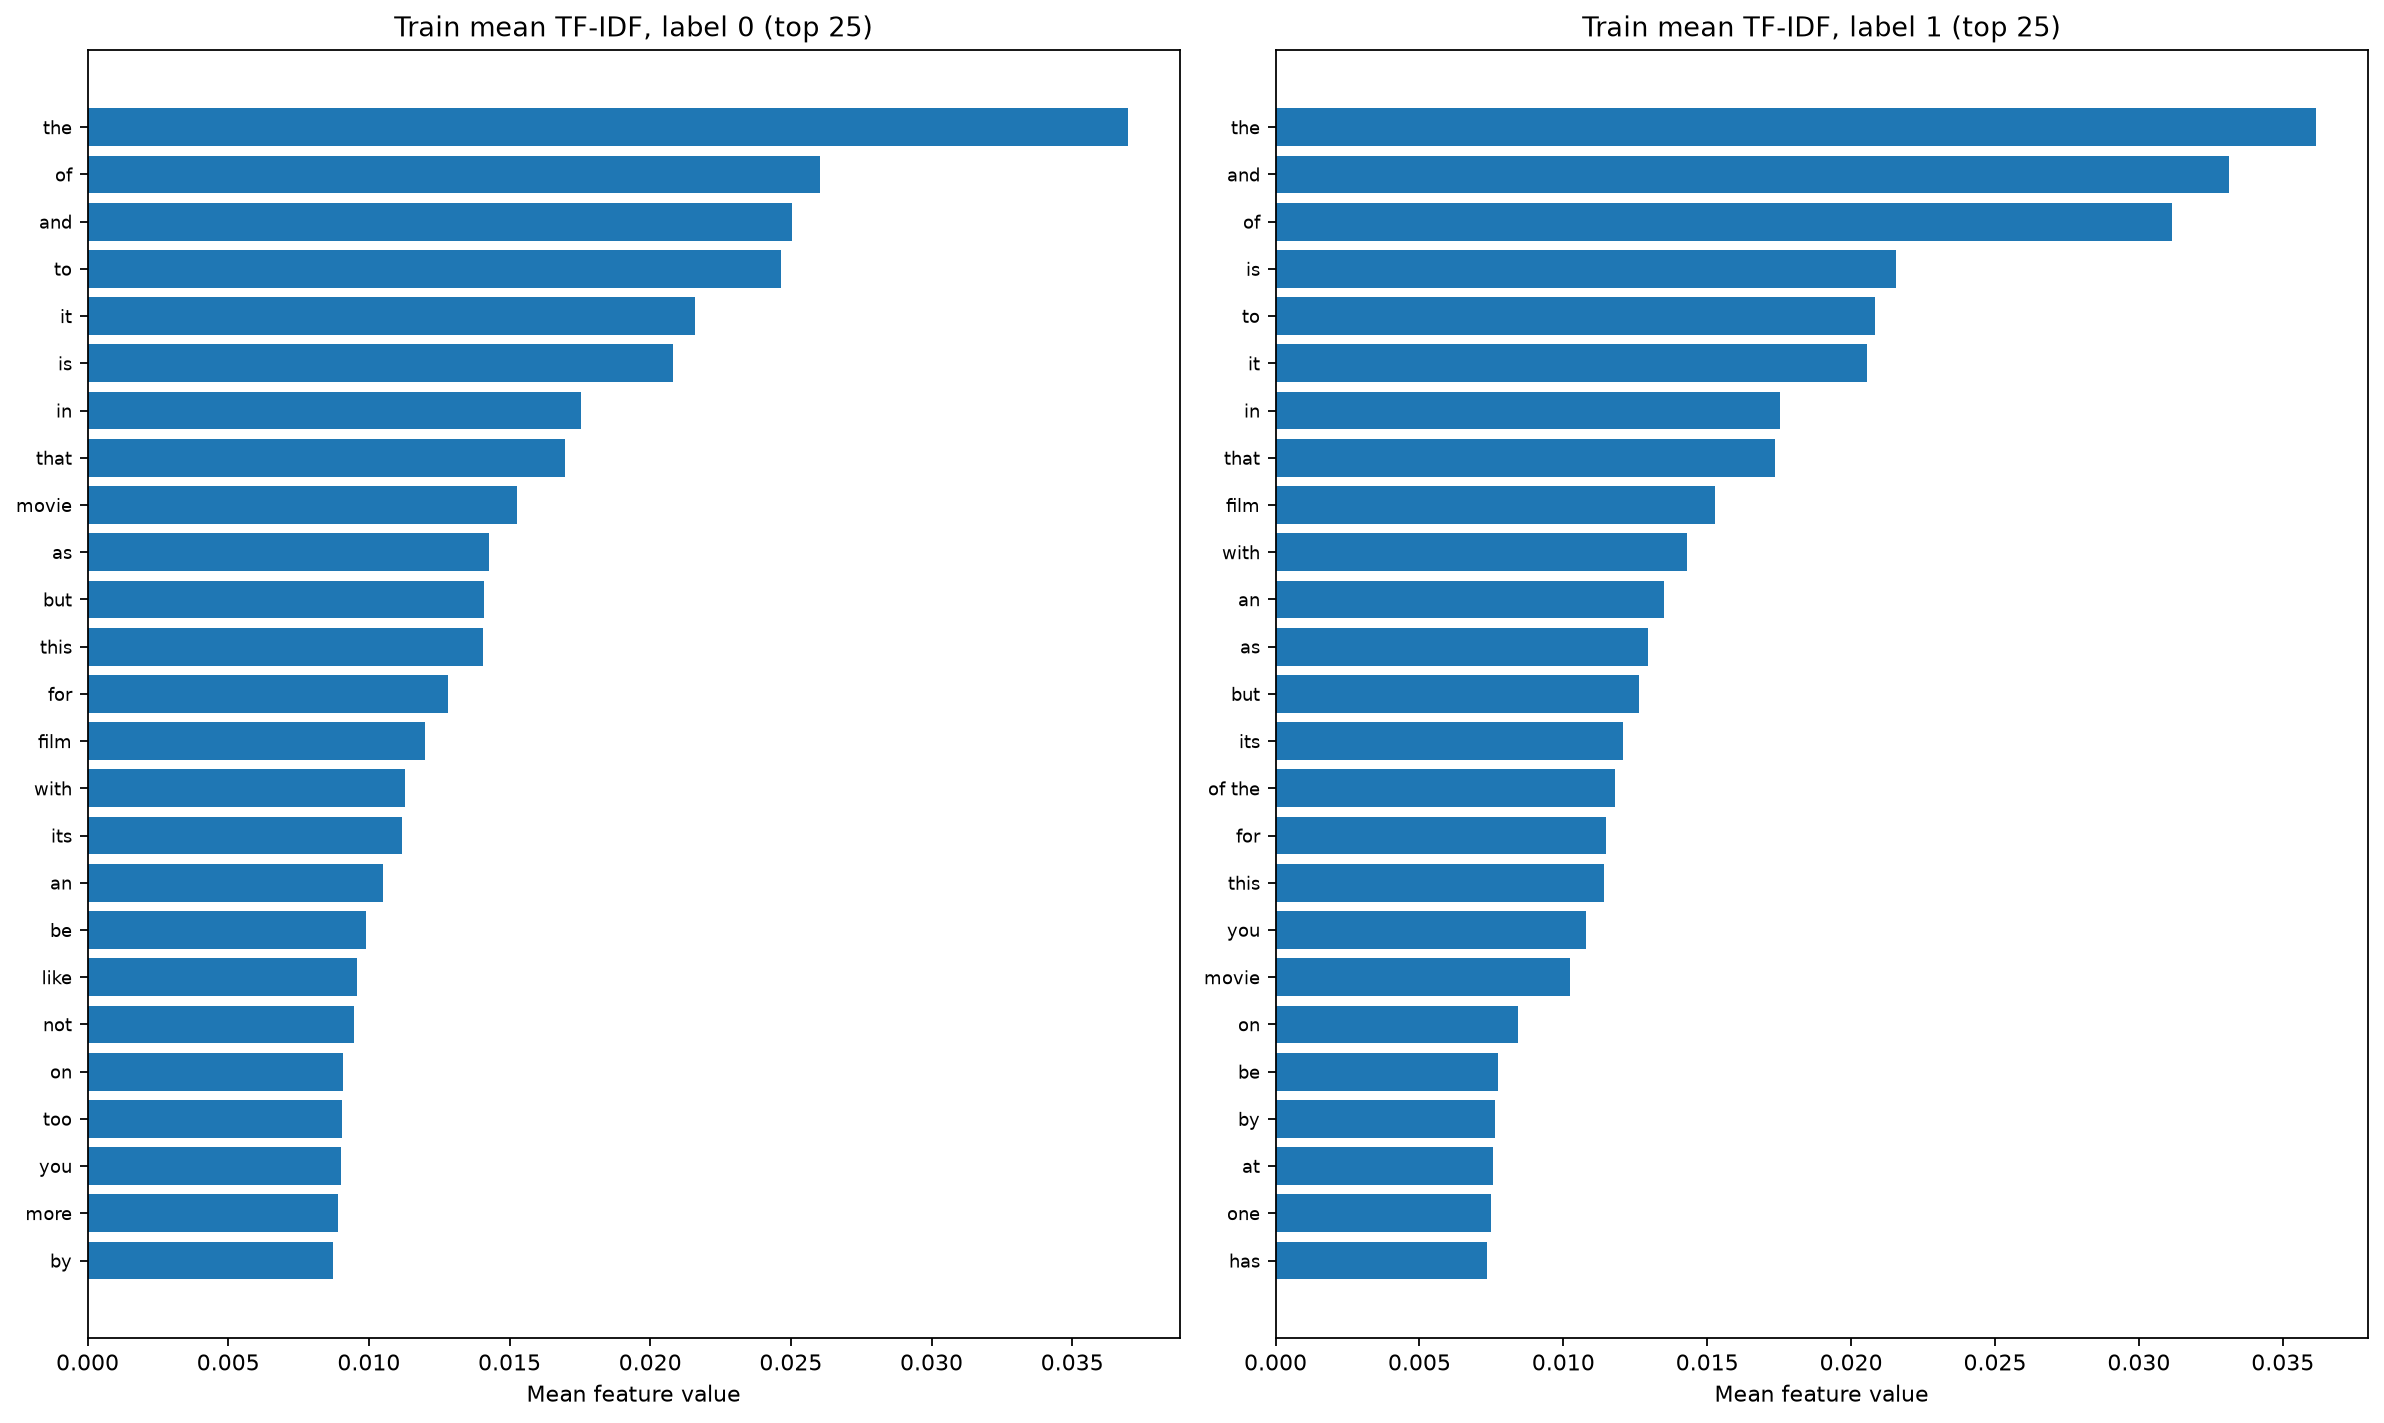

**tfidf_class_delta.png**

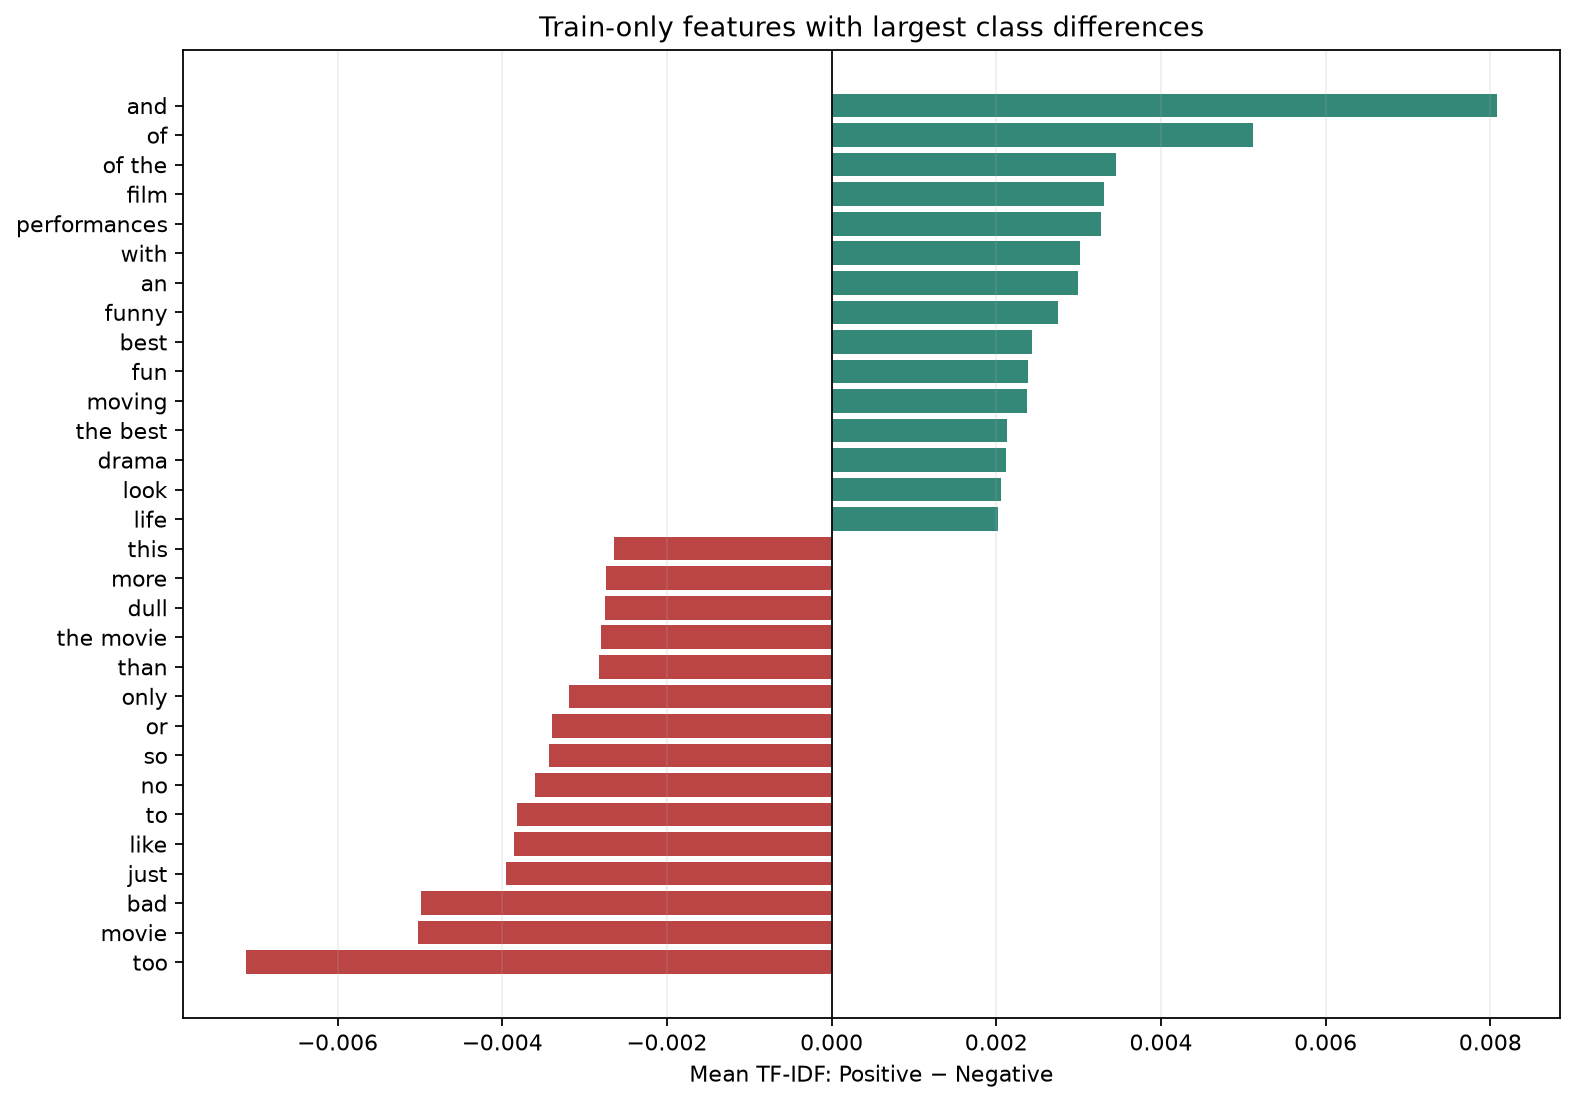

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/tfidf_features.png'),
 WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/tfidf_class_delta.png')]

In [5]:
features = session.read(session.paths["data"] / "feature_summary.json")
print(f"Ma trận TF-IDF Train Shape: {features['train_shape']}")
print(f"Độ thưa (Sparsity Density): {features['density']:.4%}")

session.show("data", ["tfidf_features.png", "tfidf_class_delta.png"])

## 6. Bước 6: Lựa chọn đặc trưng bằng kiểm định Chi-Square ($\chi^2$)

,term,chi2_score,p_value
0,too,19.729301,0.000009
1,bad,15.336423,0.000090
2,dull,9.691630,0.001851
3,boring,8.601149,0.003360
4,performances,8.212767,0.004160
5,moving,7.524682,0.006086
6,touching,7.180299,0.007371
7,portrait,7.167884,0.007422
8,feels,6.535473,0.010574
9,tv,6.241581,0.012479


**chi2_features.png**

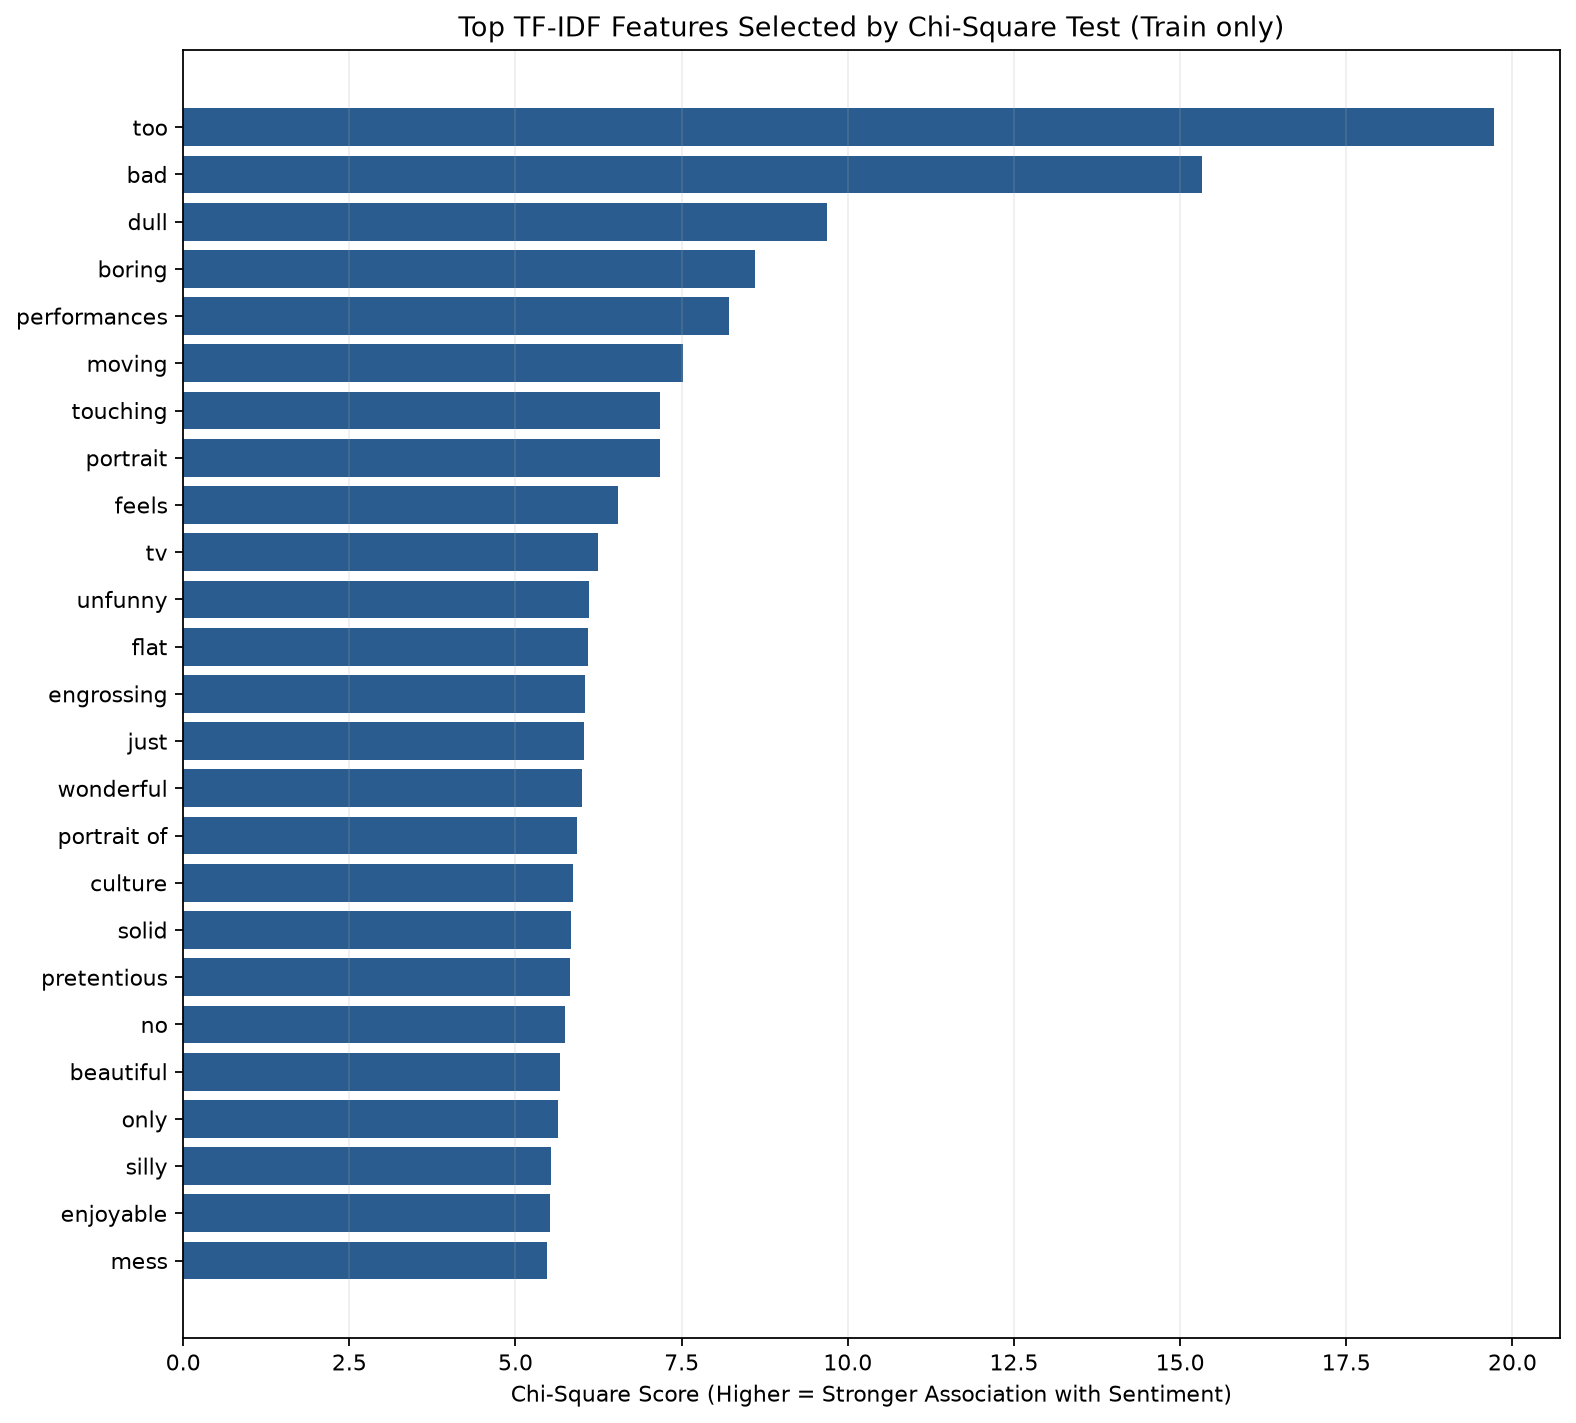

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/chi2_features.png')]

In [6]:
import pandas as pd
from IPython.display import display

chi2_data = session.read(session.paths["data"] / "chi2_features.json")
display(pd.DataFrame(chi2_data.get("terms", [])[:15]))

session.show("data", ["chi2_features.png"])

## 7. Bước 7: Tăng cường dữ liệu có kiểm soát (Text Augmentation & Guardrails)

Số mẫu Train gốc: 8,530
Số mẫu sau tăng cường: 8,804 (+274)


,original_text,text,source_word,replacement,label
0,a delightful romantic comedy with plenty of bi...,a charming romantic comedy with plenty of bite...,delightful,charming,1
1,. . . nothing scary here except for some awful...,. . . nothing scary here except for some terri...,awful,terrible,0
2,poignant and funny .,poignant and amusing .,funny,amusing,1
3,both awful and appealing .,both terrible and appealing .,awful,terrible,0
4,frequent flurries of creative belly laughs and...,frequent flurries of creative belly laughs and...,enjoyable,entertaining,1
...,...,...,...,...,...
269,"schmaltzy and unfunny , adam sandler's cartoon...","schmaltzy and humorless , adam sandler's carto...",unfunny,humorless,0
270,invincible is a wonderful movie .,invincible is a excellent movie .,wonderful,excellent,1
271,"sharp , lively , funny and ultimately sobering...","sharp , lively , amusing and ultimately soberi...",funny,amusing,1
272,this strenuously unfunny showtime deserves the...,this strenuously humorless showtime deserves t...,unfunny,humorless,0


**augmentation_counts.png**

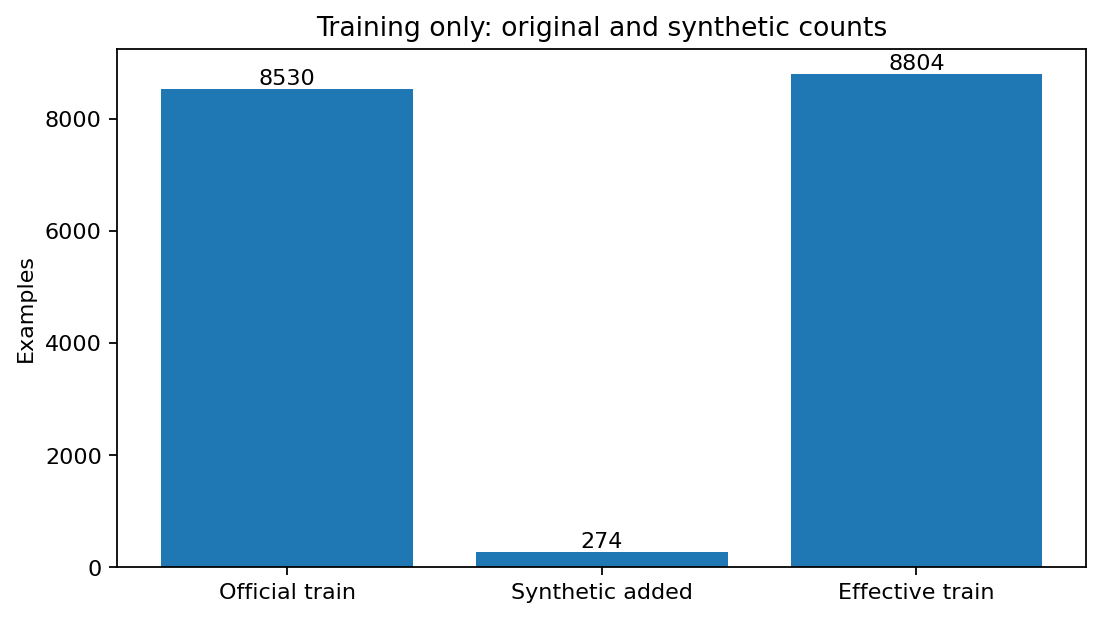

**augmentation_examples.png**

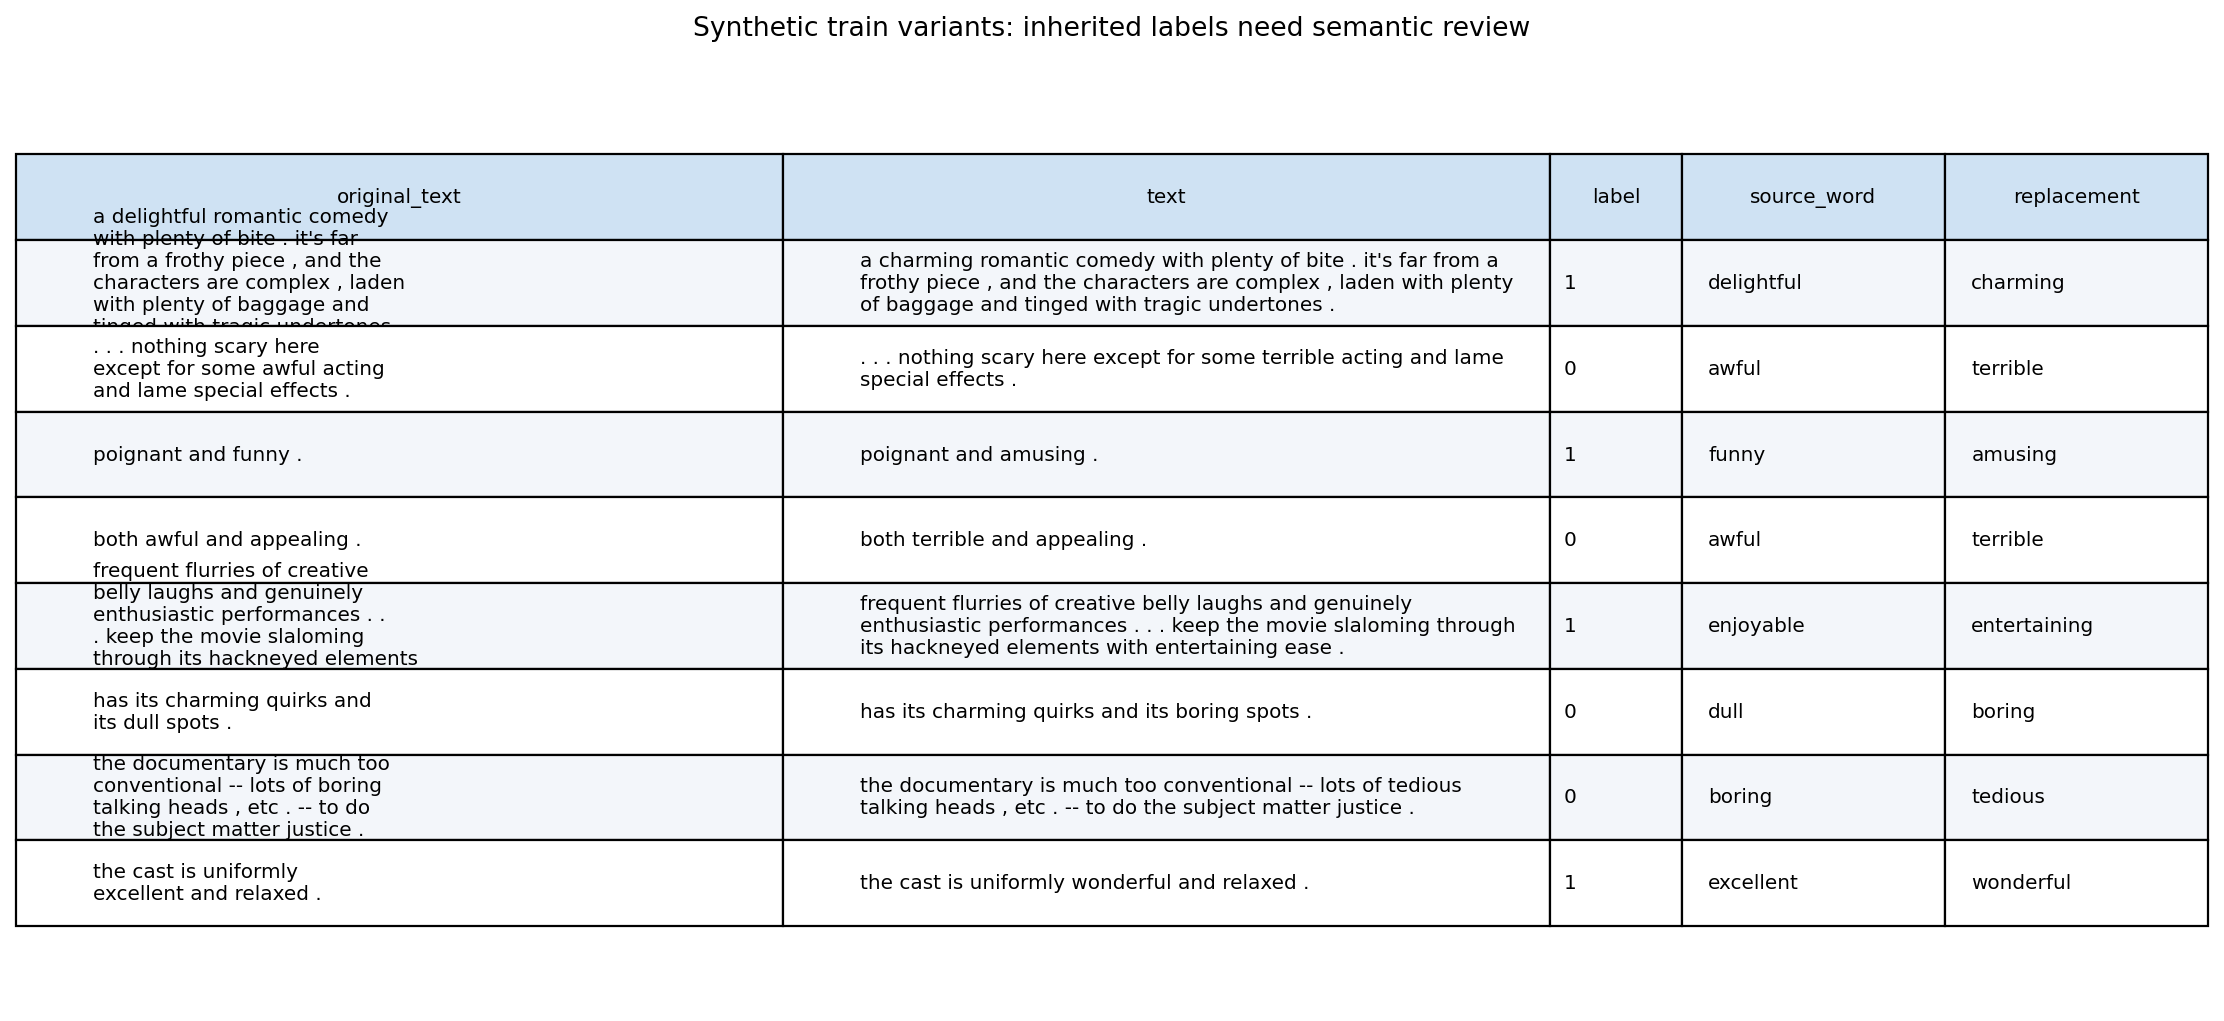

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/augmentation_counts.png'),
 WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/augmentation_examples.png')]

In [7]:
from IPython.display import display

augmentation = session.read(session.paths["augmentation"] / "augmentation.json")
print(f"Số mẫu Train gốc: {augmentation['original_train_size']:,}")
print(f"Số mẫu sau tăng cường: {augmentation['effective_train_size']:,} (+{augmentation['added_count']:,})")

display(session.table("augmentation", "augmentation.json", "records", ["original_text", "text", "source_word", "replacement", "label"]))
session.show("augmentation", ["augmentation_counts.png", "augmentation_examples.png"])